# 02 — Paradigma 1: detección supervisada en CISUTAC (bloque A)

**Pregunta:** al detectar agujeros y manchas pequeños en fotos de prendas usadas, ¿conviene reducir la foto completa, aumentar la resolución de entrada o recorrerla con *tiles* a resolución nativa? ¿Cuánto cuesta cada opción?

El EDA mostró que, al reducir la foto (2160×3840) a 640 px, la mediana del defecto queda en **4,2 px (agujeros) y 3,0 px (manchas)**, y que el baseline preliminar a 640 no encontró ningún defecto menor a 32 px. Este notebook arma el **baseline supervisado** y lo compara de forma controlada contra variantes que conservan más detalle.

| ID | Variante | Entrenamiento | Inferencia | Qué responde |
|---|---|---|---|---|
| **A0** | Foto completa 640 | foto reducida a lado mayor 640 | ídem | Baseline estándar de YOLO |
| **A1** | Más resolución | foto reducida a lado mayor 1280 (opcional 1920) | ídem | ¿Alcanza con subir `imgsz`? |
| **A2** | Tiles sólo en inferencia | modelo de A0 | tiles 640 a resolución nativa | Ablación: ¿importa que la escala de entrenamiento y la de inferencia coincidan? |
| **A3** | Tiles en entrenamiento e inferencia | tiles 640 (20 % solapamiento) | ídem, con y sin la foto completa | Hipótesis principal |
| **A3-abl** | Ablaciones de A3 | proporción de tiles sin defectos; tamaño de tile | — | Qué decisiones de diseño importan |

**Reglas del protocolo** (`reports/protocolo_experimental.md`):

- Mismo detector (**YOLO11n** preentrenado en COCO), misma semilla, mismos aumentos y el mismo **presupuesto de entrenamiento** medido en imágenes vistas.
- Todas las métricas se calculan **en coordenadas de la foto original**, con `src/detection_eval.py`: mAP@0.5, mAP@0.5:0.95, AP_small, recall por tamaño, tiempo por imagen.
- **Valid** elige épocas, umbrales y variantes. **Test se usa una sola vez**, al final, para A0 y la mejor variante.
- Holes y Spots se tratan por separado: el notebook corre un dataset por vez (`DATASET`).

> **Cómo correrlo.** Necesita los datos de CISUTAC (ver `docs/DATASETS.md`), `pip install ultralytics==8.4.209 sahi==0.14.0 pycocotools==2.0.11` y, en lo posible, GPU. Primero conviene correrlo con `MODO_PRUEBA = True` (1 época, pocas imágenes, unos minutos) para verificar que todo funciona. Cada entrenamiento y evaluación queda guardado en `results/cisutac/bloque_a/`: si se vuelve a ejecutar el notebook, **se reutilizan** y no se reentrena (salvo `REENTRENAR = True`).

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import cisutac_baseline as cb
from detection_eval import SIZE_LABELS

pd.set_option("display.max_columns", 30)
print("Datos:", cb.DATA)
print("Resultados:", cb.RESULTS)

Datos: /tmp/rewear_data
Resultados: /kaggle/working/tp_final_vision/results/cisutac/bloque_a


## 0. Parámetros

Todos los parámetros que se prueban están en esta celda o al comienzo de cada sección, para que se vea qué cambia entre variantes.

In [2]:
DATASET = 'spots'  # fijado por el lanzador de Kaggle
MODO_PRUEBA = False  # fijado por el lanzador de Kaggle
REENTRENAR = False       # True: ignora corridas guardadas y vuelve a entrenar/evaluar
EVALUAR_TEST = True  # fijado por el lanzador de Kaggle

# Comunes a todas las variantes (el único cambio entre A0, A1 y A3 es cómo se procesa la escala)
MODELO = "yolo11n.pt"    # preentrenado en COCO
SEMILLA = 0
EPOCAS_BASE = 100        # épocas para la foto completa; las demás variantes se igualan en imágenes vistas
PACIENCIA_BASE = 30      # épocas sin mejora en valid antes de cortar
CONF_EVAL = 0.001        # confianza mínima de las predicciones guardadas (bajo, para calcular mAP)

# Tiles: configuración principal (CIS-4: 97 % de los defectos entra entero en algún tile)
TILE, SOLAPAMIENTO = 640, 0.2
NEG_POR_POS = 1.0        # tiles sin defectos por cada tile con defectos
MIN_VISIBLE = 0.5        # fracción mínima de un defecto cortado para conservarlo como caja

if MODO_PRUEBA:
    EPOCAS_BASE, PACIENCIA_BASE = 1, 1
    FRACCION, LIMITE_EVAL, MAX_IMAGENES_TILES = 0.1, 3, 6
else:
    FRACCION, LIMITE_EVAL, MAX_IMAGENES_TILES = 1.0, None, None
SUFIJO = "_prueba" if MODO_PRUEBA else ""
BATCH = {640: 16, 1024: 8, 1280: 8, 1920: 4}   # se baja con la resolución para que entre en memoria

def nombre(variante):
    return f"{DATASET}_{variante}{SUFIJO}"

def pesos(run_dir):
    return Path(run_dir) / "weights" / "best.pt"

def evaluar_valid(run_name, weights, modo, **kw):
    # Evalúa en valid con la foto completa o con tiles, y nombra la evaluación según la configuración.
    detalle = (f"completa{kw.get('imgsz', 640)}" if modo == "completa" else
               f"tiles{kw.get('tile', TILE)}_o{round(100 * kw.get('overlap', SOLAPAMIENTO))}"
               + ("+completa" if kw.get("also_full") else ""))
    return cb.evaluate(f"{run_name}__valid_{detalle}", DATASET, weights, split="valid", mode=modo,
                       conf=CONF_EVAL, limit=LIMITE_EVAL, reevaluate=REENTRENAR, **kw)

In [3]:
import importlib.metadata as md
for paquete in ("ultralytics", "sahi", "pycocotools", "torch"):
    try:
        print(f"{paquete:12s} {md.version(paquete)}")
    except md.PackageNotFoundError:
        print(f"{paquete:12s} FALTA -> pip install {paquete}")
print("Dispositivo:", cb.pick_device())

ultralytics  8.4.216
sahi         0.14.0
pycocotools  2.0.11
torch        2.11.0+cu130


Dispositivo: 0


## 1. Datos

Se usan sólo las **fotos originales** con el split CISUTAC v1 (agrupado por día, `reports/cisutac/cis5_split_propuesto.csv`). Si todavía no existe `data/derived/`, la celda siguiente corre `scripts/prepare_cisutac_yolo.py`, que arma enlaces/copias, labels YOLO y las cajas COCO de referencia sin tocar los originales.

In [4]:
if not (cb.derived_dir(DATASET) / "data.yaml").exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "prepare_cisutac_yolo.py")], check=True)

gt = {split: cb.load_ground_truth(DATASET, split) for split in ("train", "valid", "test")}
pd.DataFrame({split: {"imágenes": len(g["images"]), "defectos": len(g["annotations"]),
                      "defectos por imagen": round(len(g["annotations"]) / len(g["images"]), 2)}
              for split, g in gt.items()}).T

,imágenes,defectos,defectos por imagen
train,361.0,1903.0,5.27
valid,59.0,284.0,4.81
test,66.0,311.0,4.71


Distribución de tamaños por split (lado equivalente √(ancho·alto) en px de la original). Los rangos se fijaron en el EDA, antes de entrenar. Interesa que train y valid tengan suficientes defectos chicos para poder medir la diferencia entre variantes.

In [5]:
from eda_utils import SIZE_EDGES

def rango(area):
    return SIZE_LABELS[sum(area ** 0.5 >= e for e in SIZE_EDGES)]

tamanos = pd.DataFrame({split: pd.Series([rango(a["area"]) for a in g["annotations"]]).value_counts()
                        for split, g in gt.items()}).reindex(SIZE_LABELS).fillna(0).astype(int)
tamanos.loc["COCO small (< 32 px)"] = [sum(a["area"] < 32 ** 2 for a in g["annotations"]) for g in gt.values()]
tamanos

,train,valid,test
< 8 px,403,72,71
8–16 px,451,66,69
16–32 px,408,61,67
32–64 px,303,34,48
≥ 64 px,338,51,56
COCO small (< 32 px),1262,199,207


**Por qué la escala importa.** Cada columna es un defecto chico real de valid: arriba a resolución nativa, abajo cómo queda cuando la foto completa se reduce a lado mayor 640 y 1280 (lo que recibe el modelo en A0 y A1).

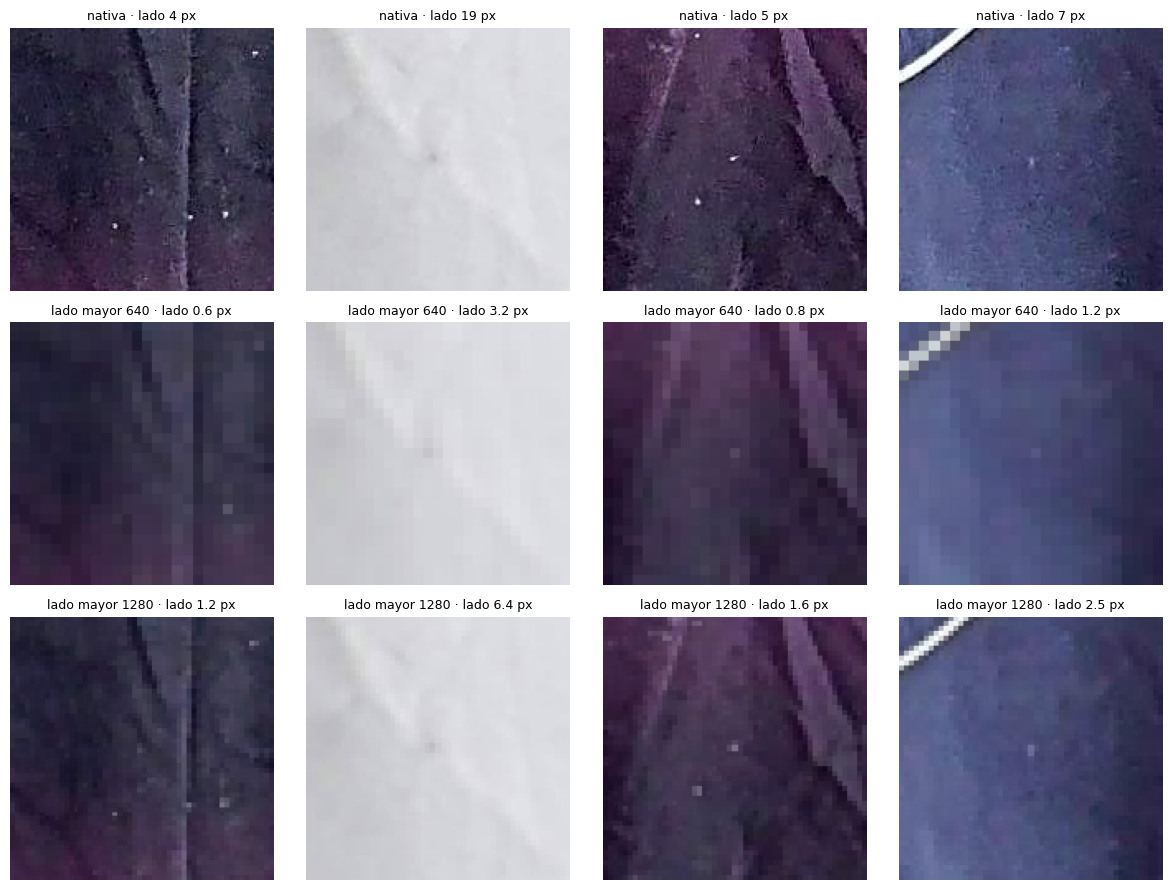

In [6]:
cb.plot_resolution_zoom(DATASET, sides=(640, 1280), n=4);

## 2. A0 — Baseline: foto completa a 640

YOLO11n preentrenado en COCO, ajustado con la foto completa reducida a lado mayor 640 (el `imgsz` por defecto de Ultralytics), con los aumentos por defecto (mosaico, escala ±50 %, giro horizontal, color). Valid sólo elige la mejor época.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/rewear_data/derived/cisutac_spots/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/tp_final_vision/results/pesos/yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=spots_A0_completa640, nbs=64, nms=None, opset=None, optimize=False, optimizer

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (1,498 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.1it/s 1.9s

                   all         59        284       0.34    0.00704     0.0056    0.00316


Speed: 0.1ms preprocess, 28.3ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to /kaggle/working/tp_final_vision/results/cisutac/bloque_a/entrenamientos/spots_A0_completa640


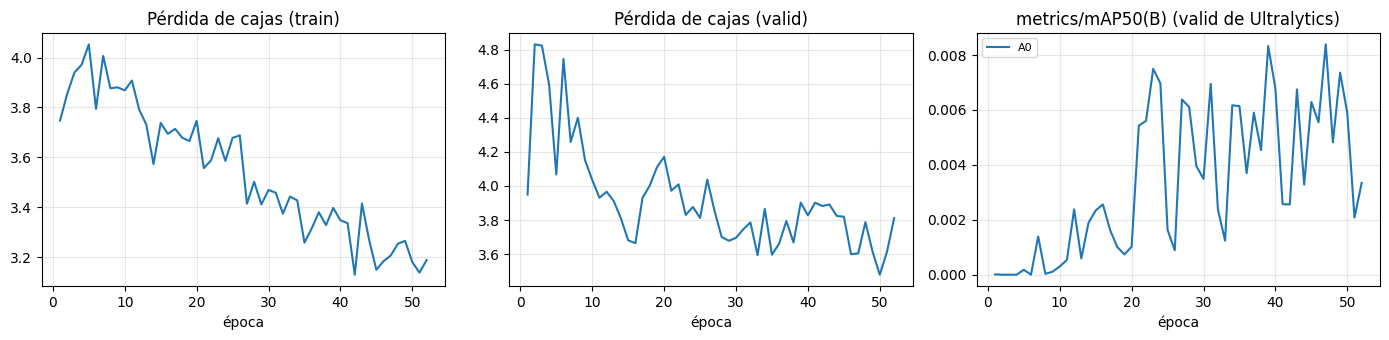

In [7]:
run_A0 = cb.train(nombre("A0_completa640"), cb.derived_dir(DATASET) / "data.yaml", imgsz=640,
                  epochs=EPOCAS_BASE, patience=PACIENCIA_BASE, batch=BATCH[640], seed=SEMILLA,
                  model=MODELO, retrain=REENTRENAR, fraction=FRACCION)
cb.plot_curves({"A0": run_A0});

Evaluación en valid, en coordenadas de la original. El umbral de confianza para precisión/recall/F1 es el que maximiza F1 en valid; mAP y AP_small no dependen de ese umbral.

In [8]:
eval_A0 = evaluar_valid(run_A0.name, pesos(run_A0), "completa", imgsz=640)
display(cb.metrics_table([eval_A0]))
display(cb.size_table([eval_A0]))

,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A0_completa640__valid_completa640,completa,0.011,0.006,0.0,0.017,0.0,0.01,0.045,0.011,0.017,0.036,1.0,0.011 (0.000–0.025)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A0_completa640__valid_completa640,0/72,0/66,0/61,2/34,1/51


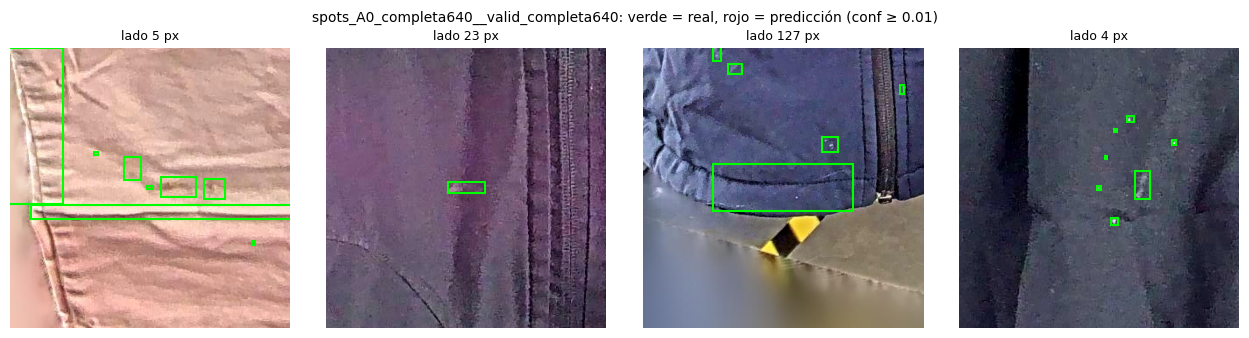

In [9]:
cb.plot_examples(DATASET, eval_A0["corrida"], n=4);

## 3. A1 — ¿Alcanza con subir la resolución de entrada?

Mismo modelo y receta, pero la foto completa entra con lado mayor más grande. Es el rival justo de los tiles: también procesa más píxeles, pero sin cortar la imagen. Se mantiene la misma cantidad de épocas que A0 (mismas imágenes vistas); el batch baja para que entre en memoria.

> 1920 necesita bastante memoria de GPU (≈ 9× los píxeles de 640). Agregarlo a la lista sólo si hay hardware.

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/rewear_data/derived/cisutac_spots/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/tp_final_vision/results/pesos/yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=spots_A1_completa1280, nbs=64, nms=None, opset=None, optimize=False, optimize

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (5,277 outputs left out)

Speed: 6.3ms preprocess, 15.7ms inference, 0.0ms loss, 1.7ms postprocess per image


Results saved to /kaggle/working/tp_final_vision/results/cisutac/bloque_a/entrenamientos/spots_A1_completa1280


,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A0_completa640__valid_completa640,completa,0.011,0.006,0.000,0.017,0.000,0.01,0.045,0.011,0.017,0.036,1.0,0.011 (0.000–0.025)
spots_A1_completa1280__valid_completa1280,completa,0.031,0.013,0.002,0.047,0.024,0.03,0.094,0.088,0.091,0.046,1.0,0.088 (0.054–0.128)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A0_completa640__valid_completa640,0/72,0/66,0/61,2/34,1/51
spots_A1_completa1280__valid_completa1280,0/72,4/66,11/61,5/34,5/51


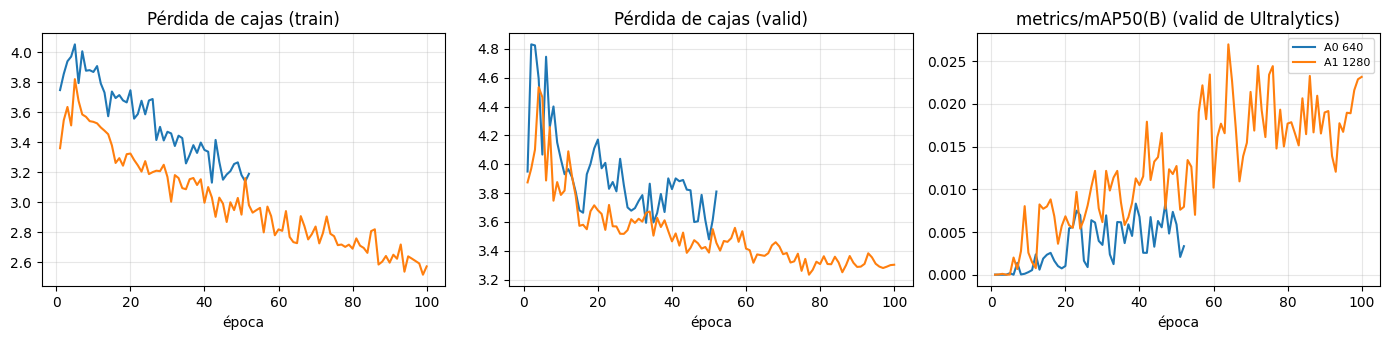

In [10]:
RESOLUCIONES_A1 = [1280]          # opcional: [1280, 1920]

runs_A1, evals_A1 = {}, []
for imgsz in RESOLUCIONES_A1:
    run = cb.train(nombre(f"A1_completa{imgsz}"), cb.derived_dir(DATASET) / "data.yaml", imgsz=imgsz,
                   epochs=EPOCAS_BASE, patience=PACIENCIA_BASE, batch=BATCH[imgsz], seed=SEMILLA,
                   model=MODELO, retrain=REENTRENAR, fraction=FRACCION)
    runs_A1[f"A1 {imgsz}"] = run
    evals_A1.append(evaluar_valid(run.name, pesos(run), "completa", imgsz=imgsz))

cb.plot_curves({"A0 640": run_A0, **runs_A1})
display(cb.metrics_table([eval_A0, *evals_A1]))
display(cb.size_table([eval_A0, *evals_A1]))

## 4. A2 — Tiles sólo en inferencia (ablación)

Se toma el modelo **ya entrenado en A0** y se lo aplica con tiles de 640 a resolución nativa (SAHI, fusión NMS a IoU 0,5), con y sin sumar la predicción de la foto completa. En el EDA esto **empeoró** el mAP: en los tiles los defectos se ven ~6 veces más grandes que en el entrenamiento. Se repite acá para que la comparación quede en la misma tabla.

In [11]:
evals_A2 = [evaluar_valid(run_A0.name, pesos(run_A0), "tiles", tile=TILE, overlap=SOLAPAMIENTO, also_full=full)
            for full in (False, True)]
display(cb.metrics_table([eval_A0, *evals_A2]))
display(cb.size_table([eval_A0, *evals_A2]))

2026-11-21 15:13:26,783 - sahi - WARNING - ignoring invalid prediction with bbox: [2160, 0.4302177429199219, 2160, 50.56414031982422] (ultralytics.py:285)


,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A0_completa640__valid_completa640,completa,0.011,0.006,0.0,0.017,0.0,0.01,0.045,0.011,0.017,0.036,1.000,0.011 (0.000–0.025)
spots_A0_completa640__valid_tiles640_o20,tiles,0.001,0.000,0.0,0.001,0.0,0.03,0.014,0.025,0.018,0.486,31.186,0.025 (0.003–0.055)
spots_A0_completa640__valid_tiles640_o20+completa,tiles,0.004,0.002,0.0,0.017,0.0,0.03,0.017,0.032,0.022,0.551,32.186,0.032 (0.008–0.066)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A0_completa640__valid_completa640,0/72,0/66,0/61,2/34,1/51
spots_A0_completa640__valid_tiles640_o20,1/72,6/66,0/61,0/34,0/51
spots_A0_completa640__valid_tiles640_o20+completa,1/72,6/66,0/61,1/34,1/51


## 5. Dataset de tiles

Para entrenar a la misma escala con la que se infiere, cada foto de train y valid se recorre con la misma grilla que usa SAHI en inferencia. Cada tile se clasifica en:

- **con defecto:** contiene al menos un defecto que conserva `MIN_VISIBLE` (50 %) de su área. Las cajas cortadas se recortan al tile;
- **sin defecto:** no toca ningún defecto;
- **descartado:** sólo tiene fragmentos chicos de defectos cortados. Si se usaran como negativos, le enseñarían al modelo que medio agujero "no es defecto".

Como hay ~32 tiles por foto y la mayoría no tiene defectos, se toman `NEG_POR_POS` tiles sin defecto por cada tile con defecto (muestreo con semilla). Esa proporción es una decisión de diseño y se estudia en la sección 7.

**Presupuesto de entrenamiento.** El dataset de tiles tiene más imágenes que el de fotos completas, así que con las mismas épocas el modelo vería muchos más ejemplos. Para comparar en igualdad de condiciones se ajustan las épocas para ver aproximadamente la **misma cantidad de imágenes** que A0 (`cb.equivalent_epochs`).

In [12]:
yaml_tiles, stats_tiles = cb.build_tile_dataset(DATASET, tile=TILE, overlap=SOLAPAMIENTO, neg_per_pos=NEG_POR_POS,
                                                seed=SEMILLA, min_visible=MIN_VISIBLE, max_images=MAX_IMAGENES_TILES)
display(pd.DataFrame(stats_tiles).T)

n_completas = len(gt["train"]["images"]) if not MAX_IMAGENES_TILES else MAX_IMAGENES_TILES
def presupuesto(stats):
    # Épocas y paciencia equivalentes en imágenes vistas a EPOCAS_BASE sobre fotos completas.
    epocas = cb.equivalent_epochs(EPOCAS_BASE, n_completas, stats["train"]["tiles_totales"],
                                  minimum=1 if MODO_PRUEBA else 10)
    return epocas, max(1, round(PACIENCIA_BASE * epocas / EPOCAS_BASE))

EPOCAS_TILES, PACIENCIA_TILES = presupuesto(stats_tiles)
print(f"Épocas para tiles: {EPOCAS_TILES} (paciencia {PACIENCIA_TILES}) "
      f"≈ {EPOCAS_BASE} épocas × {n_completas} fotos completas")

,imagenes_originales,tiles_posibles,tiles_con_defecto,tiles_sin_defecto_disponibles,tiles_sin_defecto_usados,tiles_descartados_por_fragmentos,tiles_totales,cajas
train,361,11552,1253,10066,1253,233,2506,3105
valid,59,1840,234,1564,234,42,468,487


Épocas para tiles: 14 (paciencia 4) ≈ 100 épocas × 361 fotos completas


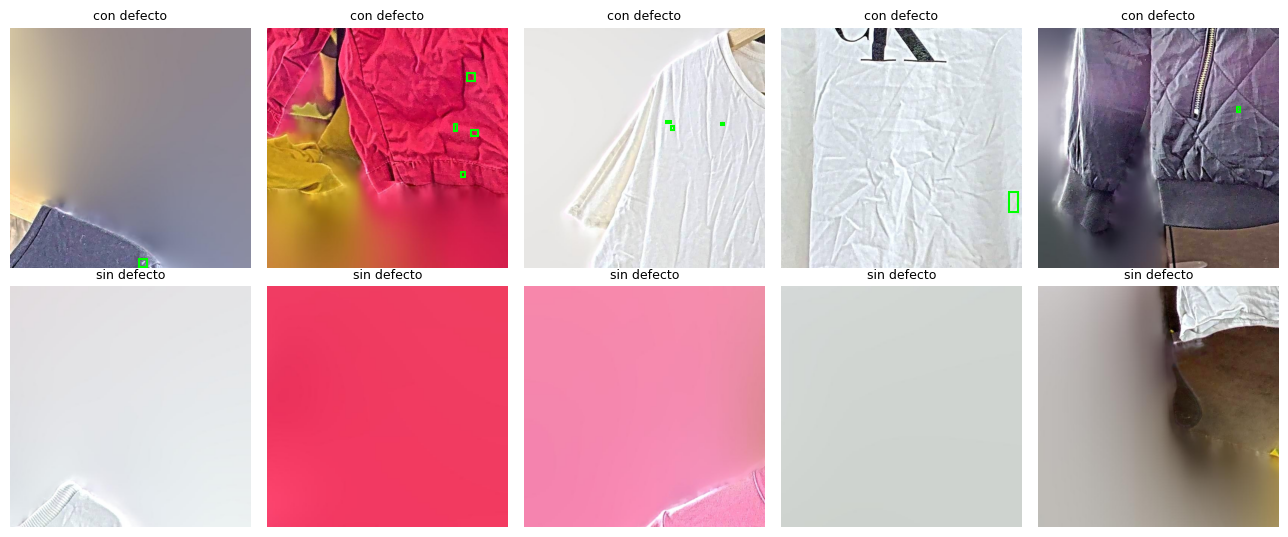

In [13]:
cb.plot_tile_samples(yaml_tiles, n=5);

## 6. A3 — Entrenar e inferir con tiles

Mismo YOLO11n, misma receta y presupuesto equivalente. En valid se infiere con SAHI sobre las **fotos originales completas** (no sobre los tiles), así que la evaluación es exactamente la misma que en A0–A2. Se prueba también sumar la predicción de la foto completa a 640, que en el EDA recuperaba defectos más grandes que un tile.

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/rewear_data/derived/cisutac_spots_tiles/t640_o20/data_neg1_s0.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=14, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/tp_final_vision/results/pesos/yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=spots_A3_tiles640_neg1, nbs=64, nms=None, opset=None, o

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (2,527 outputs left out)

Speed: 0.2ms preprocess, 3.1ms inference, 0.0ms loss, 0.9ms postprocess per image


Results saved to /kaggle/working/tp_final_vision/results/cisutac/bloque_a/entrenamientos/spots_A3_tiles640_neg1


,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A0_completa640__valid_completa640,completa,0.011,0.006,0.000,0.017,0.000,0.01,0.045,0.011,0.017,0.036,1.000,0.011 (0.000–0.025)
spots_A1_completa1280__valid_completa1280,completa,0.031,0.013,0.002,0.047,0.024,0.03,0.094,0.088,0.091,0.046,1.000,0.088 (0.054–0.128)
spots_A0_completa640__valid_tiles640_o20,tiles,0.001,0.000,0.000,0.001,0.000,0.03,0.014,0.025,0.018,0.486,31.186,0.025 (0.003–0.055)
spots_A0_completa640__valid_tiles640_o20+completa,tiles,0.004,0.002,0.000,0.017,0.000,0.03,0.017,0.032,0.022,0.551,32.186,0.032 (0.008–0.066)
spots_A3_tiles640_neg1__valid_tiles640_o20,tiles,0.022,0.006,0.008,0.001,0.001,0.05,0.090,0.067,0.077,0.449,31.186,0.067 (0.033–0.104)
spots_A3_tiles640_neg1__valid_tiles640_o20+completa,tiles,0.022,0.006,0.008,0.001,0.005,0.05,0.090,0.070,0.079,0.518,32.186,0.070 (0.036–0.108)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A0_completa640__valid_completa640,0/72,0/66,0/61,2/34,1/51
spots_A1_completa1280__valid_completa1280,0/72,4/66,11/61,5/34,5/51
spots_A0_completa640__valid_tiles640_o20,1/72,6/66,0/61,0/34,0/51
spots_A0_completa640__valid_tiles640_o20+completa,1/72,6/66,0/61,1/34,1/51
spots_A3_tiles640_neg1__valid_tiles640_o20,8/72,6/66,4/61,1/34,0/51
spots_A3_tiles640_neg1__valid_tiles640_o20+completa,8/72,6/66,4/61,2/34,0/51


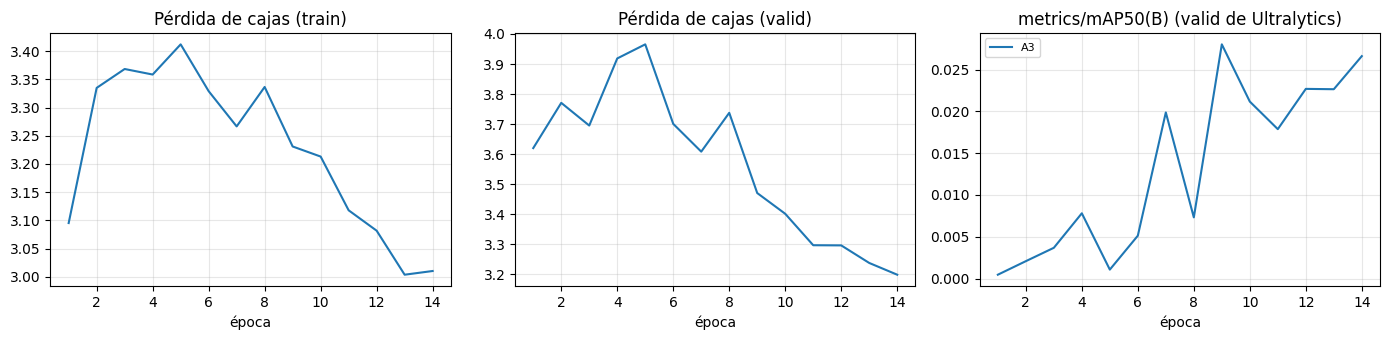

In [14]:
def entrenar_tiles(variante, data_yaml, stats, tile=TILE):
    epocas, paciencia = presupuesto(stats)
    return cb.train(nombre(variante), data_yaml, imgsz=tile, epochs=epocas, patience=paciencia,
                    batch=BATCH[tile], seed=SEMILLA, model=MODELO, retrain=REENTRENAR)

run_A3 = entrenar_tiles(f"A3_tiles{TILE}_neg{NEG_POR_POS:g}", yaml_tiles, stats_tiles)
cb.plot_curves({"A3": run_A3})

evals_A3 = [evaluar_valid(run_A3.name, pesos(run_A3), "tiles", tile=TILE, overlap=SOLAPAMIENTO, also_full=full)
            for full in (False, True)]
display(cb.metrics_table([eval_A0, *evals_A1, *evals_A2, *evals_A3]))
display(cb.size_table([eval_A0, *evals_A1, *evals_A2, *evals_A3]))

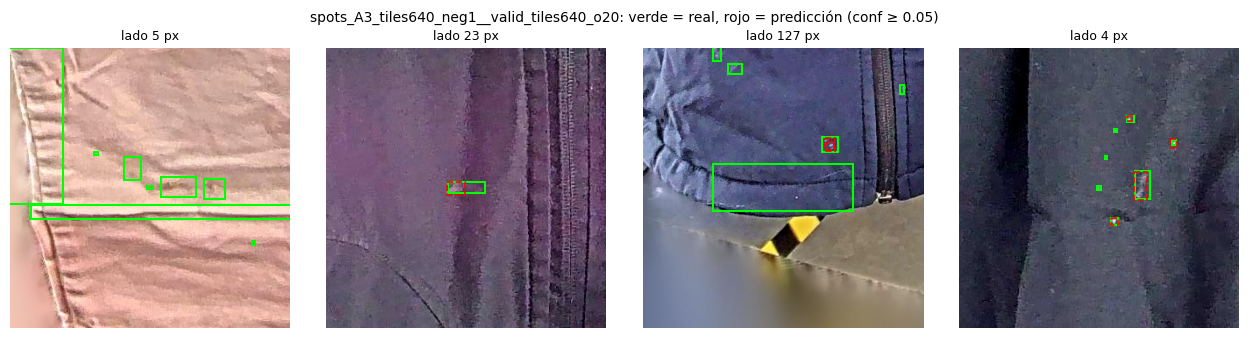

In [15]:
cb.plot_examples(DATASET, evals_A3[0]["corrida"], n=4);

## 7. Ablaciones de A3 (sólo en valid)

Se cambia **un factor por vez** a partir de la configuración principal de A3:

1. **Proporción de tiles sin defecto** (`NEG_POR_POS`). Con 0 el modelo nunca ve tela sana y se espera que confunda costuras, botones y estampados con defectos. Con muchos negativos aprende mejor el fondo, pero puede volverse conservador y perder recall.
2. **Tamaño de tile.** Tiles más chicos dan más contexto local y más pasadas (más costo); tiles más grandes, menos pasadas y más defectos enteros (CIS-4).

La inferencia usa siempre la grilla del mismo tamaño que el entrenamiento.

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/rewear_data/derived/cisutac_spots_tiles/t640_o20/data_neg0_s0.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=29, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/tp_final_vision/results/pesos/yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=spots_A3_tiles640_neg0, nbs=64, nms=None, opset=None, o

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (6,229 outputs left out)

Speed: 0.3ms preprocess, 2.7ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to /kaggle/working/tp_final_vision/results/cisutac/bloque_a/entrenamientos/spots_A3_tiles640_neg3


,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A3_tiles640_neg1__valid_tiles640_o20,tiles,0.022,0.006,0.008,0.001,0.001,0.05,0.090,0.067,0.077,0.449,31.186,0.067 (0.033–0.104)
spots_A3_tiles640_neg0__valid_tiles640_o20,tiles,0.039,0.014,0.017,0.019,0.004,0.09,0.137,0.130,0.133,0.457,31.186,0.130 (0.081–0.179)
spots_A3_tiles640_neg3__valid_tiles640_o20,tiles,0.006,0.002,0.003,0.001,0.000,0.01,0.034,0.049,0.040,0.418,31.186,0.049 (0.024–0.074)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A3_tiles640_neg1__valid_tiles640_o20,8/72,6/66,4/61,1/34,0/51
spots_A3_tiles640_neg0__valid_tiles640_o20,8/72,10/66,9/61,6/34,4/51
spots_A3_tiles640_neg3__valid_tiles640_o20,2/72,10/66,2/61,0/34,0/51


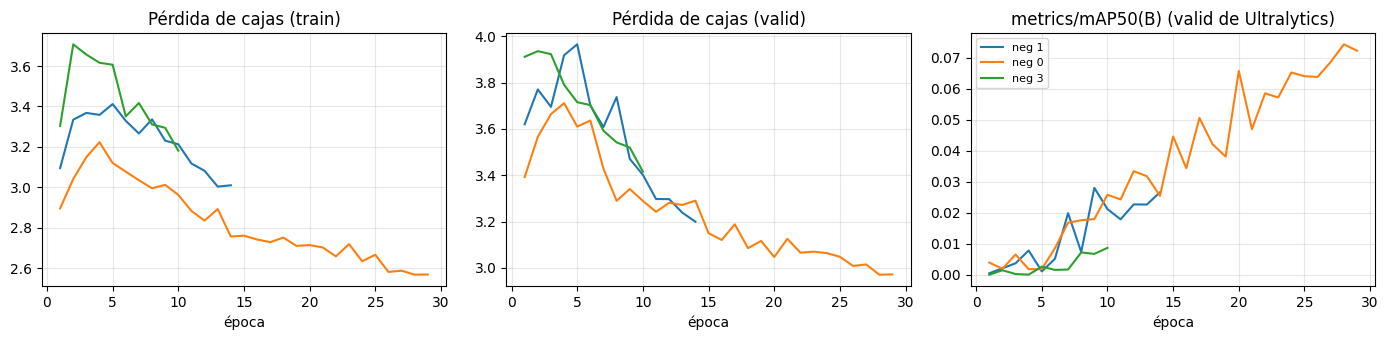

In [16]:
ABLACION_NEGATIVOS = [0.0, 3.0]     # además del valor principal NEG_POR_POS

evals_neg, runs_neg = [], {}
for neg in ABLACION_NEGATIVOS:
    yaml_n, stats_n = cb.build_tile_dataset(DATASET, tile=TILE, overlap=SOLAPAMIENTO, neg_per_pos=neg, seed=SEMILLA,
                                            min_visible=MIN_VISIBLE, max_images=MAX_IMAGENES_TILES)
    run = entrenar_tiles(f"A3_tiles{TILE}_neg{neg:g}", yaml_n, stats_n)
    runs_neg[f"neg {neg:g}"] = run
    evals_neg.append(evaluar_valid(run.name, pesos(run), "tiles", tile=TILE, overlap=SOLAPAMIENTO))

cb.plot_curves({f"neg {NEG_POR_POS:g}": run_A3, **runs_neg})
display(cb.metrics_table([evals_A3[0], *evals_neg]))
display(cb.size_table([evals_A3[0], *evals_neg]))

In [17]:
ABLACION_TILES = [1024]             # opcional: [512, 1024]; 512 tiene ~2× el costo de inferencia de 640

evals_tile = []
for tile in ABLACION_TILES:
    yaml_t, stats_t = cb.build_tile_dataset(DATASET, tile=tile, overlap=SOLAPAMIENTO, neg_per_pos=NEG_POR_POS,
                                            seed=SEMILLA, min_visible=MIN_VISIBLE, max_images=MAX_IMAGENES_TILES)
    run = entrenar_tiles(f"A3_tiles{tile}_neg{NEG_POR_POS:g}", yaml_t, stats_t, tile=tile)
    evals_tile.append(evaluar_valid(run.name, pesos(run), "tiles", tile=tile, overlap=SOLAPAMIENTO))

display(cb.metrics_table([evals_A3[0], *evals_tile]))
display(cb.size_table([evals_A3[0], *evals_tile]))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/rewear_data/derived/cisutac_spots_tiles/t1024_o20/data_neg1_s0.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/tp_final_vision/results/pesos/yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=spots_A3_tiles1024_neg1, nbs=64, nms=None, opset=None,

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (5,140 outputs left out)

Speed: 1.1ms preprocess, 7.2ms inference, 0.0ms loss, 1.3ms postprocess per image


Results saved to /kaggle/working/tp_final_vision/results/cisutac/bloque_a/entrenamientos/spots_A3_tiles1024_neg1


,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A3_tiles640_neg1__valid_tiles640_o20,tiles,0.022,0.006,0.008,0.001,0.001,0.05,0.09,0.067,0.077,0.449,31.186,0.067 (0.033–0.104)
spots_A3_tiles1024_neg1__valid_tiles1024_o20,tiles,0.018,0.007,0.009,0.004,0.000,0.04,0.11,0.070,0.086,0.366,14.695,0.070 (0.032–0.114)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A3_tiles640_neg1__valid_tiles640_o20,8/72,6/66,4/61,1/34,0/51
spots_A3_tiles1024_neg1__valid_tiles1024_o20,5/72,8/66,6/61,1/34,0/51


## 8. Comparación de todas las variantes en valid

La tabla junta todas las evaluaciones de valid de este dataset que existan en `results/` (también las de corridas anteriores). Los gráficos muestran dónde ayuda cada variante: el recall por tamaño responde directamente la hipótesis (¿mejoran los defectos < 32 px?) y el gráfico de costo muestra a qué precio.

In [18]:
todas = [json.loads(p.read_text()) for p in sorted((cb.RESULTS / "evaluaciones").glob(f"{DATASET}_*__valid_*/metricas.json"))]
todas = [m for m in todas if ("_prueba" in m["corrida"]) == MODO_PRUEBA]  # no mezclar pruebas con corridas reales
tabla_valid = cb.metrics_table(todas).sort_values("mAP@0.5", ascending=False)
tabla_valid

,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A3_tiles640_neg0__valid_tiles640_o20,tiles,0.039,0.014,0.017,0.019,0.004,0.09,0.137,0.130,0.133,0.457,31.186,0.130 (0.081–0.179)
spots_A1_completa1280__valid_completa1280,completa,0.031,0.013,0.002,0.047,0.024,0.03,0.094,0.088,0.091,0.046,1.000,0.088 (0.054–0.128)
spots_A3_tiles640_neg1__valid_tiles640_o20,tiles,0.022,0.006,0.008,0.001,0.001,0.05,0.090,0.067,0.077,0.449,31.186,0.067 (0.033–0.104)
spots_A3_tiles640_neg1__valid_tiles640_o20+completa,tiles,0.022,0.006,0.008,0.001,0.005,0.05,0.090,0.070,0.079,0.518,32.186,0.070 (0.036–0.108)
spots_A3_tiles1024_neg1__valid_tiles1024_o20,tiles,0.018,0.007,0.009,0.004,0.000,0.04,0.110,0.070,0.086,0.366,14.695,0.070 (0.032–0.114)
spots_A0_completa640__valid_completa640,completa,0.011,0.006,0.000,0.017,0.000,0.01,0.045,0.011,0.017,0.036,1.000,0.011 (0.000–0.025)
spots_A3_tiles640_neg3__valid_tiles640_o20,tiles,0.006,0.002,0.003,0.001,0.000,0.01,0.034,0.049,0.040,0.418,31.186,0.049 (0.024–0.074)
spots_A0_completa640__valid_tiles640_o20+completa,tiles,0.004,0.002,0.000,0.017,0.000,0.03,0.017,0.032,0.022,0.551,32.186,0.032 (0.008–0.066)
spots_A0_completa640__valid_tiles640_o20,tiles,0.001,0.000,0.000,0.001,0.000,0.03,0.014,0.025,0.018,0.486,31.186,0.025 (0.003–0.055)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A0_completa640__valid_completa640,0/72,0/66,0/61,2/34,1/51
spots_A0_completa640__valid_tiles640_o20,1/72,6/66,0/61,0/34,0/51
spots_A0_completa640__valid_tiles640_o20+completa,1/72,6/66,0/61,1/34,1/51
spots_A1_completa1280__valid_completa1280,0/72,4/66,11/61,5/34,5/51
spots_A3_tiles1024_neg1__valid_tiles1024_o20,5/72,8/66,6/61,1/34,0/51
spots_A3_tiles640_neg0__valid_tiles640_o20,8/72,10/66,9/61,6/34,4/51
spots_A3_tiles640_neg1__valid_tiles640_o20,8/72,6/66,4/61,1/34,0/51
spots_A3_tiles640_neg1__valid_tiles640_o20+completa,8/72,6/66,4/61,2/34,0/51
spots_A3_tiles640_neg3__valid_tiles640_o20,2/72,10/66,2/61,0/34,0/51


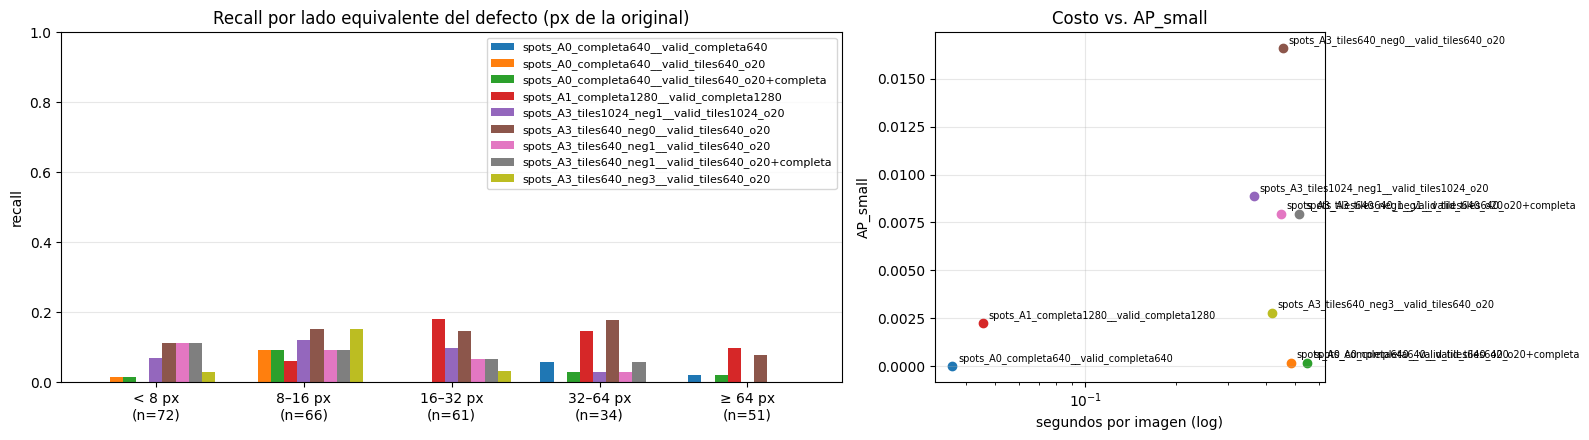

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2, 1]})
cb.plot_recall_by_size(todas, ax=axes[0])
cb.plot_cost_vs_quality(todas, metric="AP_small", ax=axes[1])
plt.tight_layout()
display(cb.size_table(todas))

## 9. Selección en valid y evaluación única en test

**Criterio fijado antes de mirar test:** se elige la variante con tiles de mayor **mAP@0.5 en valid** (métrica principal del protocolo); en caso de empate se prefiere la más barata. En test se evalúan sólo el baseline A0 y esa variante, cada una con **su umbral de confianza elegido en valid**.

Con un test de 64 (Holes) y 66 (Spots) fotos, si los intervalos de confianza se superponen **no se puede afirmar una mejora**.

Baseline : spots_A0_completa640__valid_completa640
Elegida  : spots_A3_tiles640_neg0__valid_tiles640_o20


,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A0_completa640__test_completa640,completa,0.002,0.000,0.002,0.000,0.006,0.01,0.045,0.010,0.016,0.038,1.0,0.010 (0.000–0.023)
spots_A3_tiles640_neg0__test_tiles640_o20,tiles,0.097,0.037,0.044,0.051,0.004,0.09,0.165,0.177,0.171,0.478,32.0,0.177 (0.125–0.238)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A0_completa640__test_completa640,0/71,0/69,1/67,1/48,1/56
spots_A3_tiles640_neg0__test_tiles640_o20,7/71,15/69,17/67,11/48,5/56


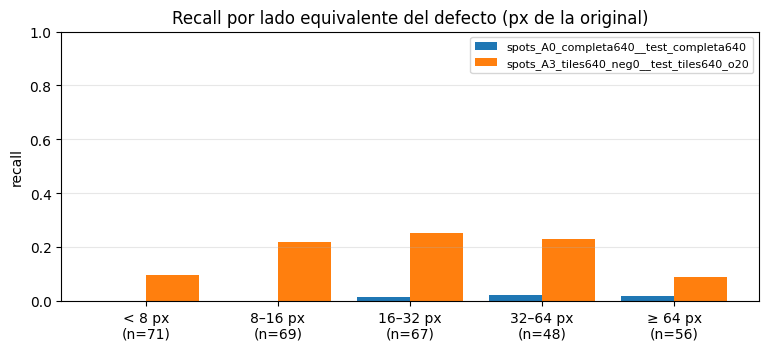

In [20]:
con_tiles = [m for m in todas if m["modo"] == "tiles" and "A3_" in m["corrida"]]
mejor = max(con_tiles, key=lambda m: (m["mAP@0.5"], -m["segundos_por_imagen"])) if con_tiles else None
print("Baseline :", eval_A0["corrida"])
print("Elegida  :", mejor and mejor["corrida"])

if EVALUAR_TEST and mejor:
    finales = []
    for m in (eval_A0, mejor):
        finales.append(cb.evaluate(m["corrida"].replace("__valid_", "__test_"), DATASET, m["pesos"], split="test",
                                   mode=m["modo"], imgsz=m["imgsz"], tile=m["tile"], overlap=m["solapamiento"],
                                   also_full=m["tambien_completa"], conf=CONF_EVAL, threshold=m["umbral_confianza"],
                                   confirm_test=True))
    display(cb.metrics_table(finales))
    display(cb.size_table(finales))
    cb.plot_recall_by_size(finales)
else:
    print("Test no evaluado (EVALUAR_TEST = False).")

## 10. Conclusiones — Spots (corrida completa en valid y evaluación única en test)

Corrida en Kaggle (GPU, `MODO_PRUEBA = False`, `EVALUAR_TEST = True`, semilla 0). Valid: 59 fotos, 284 manchas (199 < 32 px). Test: 66 fotos, 311 manchas (207 < 32 px).

### Valid

| Variante | mAP@0.5 | AP_small | Precisión | Recall (IC 95 %) | Encontrados < 32 px | Encontrados ≥ 32 px | s / imagen |
|---|---|---|---|---|---|---|---|
| A0 · completa 640 | 0,011 | 0,000 | 0,045 | 0,011 (0,00–0,03) | 0 / 199 | 3 / 85 | 0,04 |
| A1 · completa 1280 | 0,031 | 0,002 | 0,094 | 0,088 (0,05–0,13) | 15 / 199 | **10 / 85** | 0,05 |
| A2 · modelo A0 + tiles | 0,001 | 0,000 | 0,014 | 0,025 (0,00–0,06) | 7 / 199 | 0 / 85 | 0,49 |
| A2 + foto completa | 0,004 | 0,000 | 0,017 | 0,032 (0,01–0,07) | 7 / 199 | 2 / 85 | 0,55 |
| **A3 · tiles 640 (neg 0)** | **0,039** | **0,017** | **0,137** | **0,130 (0,08–0,18)** | **27 / 199** | **10 / 85** | 0,46 |
| A3 · tiles 640 (neg 1) | 0,022 | 0,008 | 0,090 | 0,067 (0,03–0,10) | 18 / 199 | 1 / 85 | 0,45 |
| A3 neg 1 + foto completa | 0,022 | 0,008 | 0,090 | 0,070 (0,04–0,11) | 18 / 199 | 2 / 85 | 0,52 |
| A3 · neg 3 | 0,006 | 0,003 | 0,034 | 0,049 (0,02–0,07) | 14 / 199 | 0 / 85 | 0,42 |
| A3 · tile 1024 | 0,018 | 0,009 | 0,110 | 0,070 (0,03–0,11) | 19 / 199 | 1 / 85 | 0,37 |

### Test (una sola vez, umbral de confianza elegido en valid)

| Variante | mAP@0.5 | mAP@0.5:0.95 | AP_small | Precisión | Recall (IC 95 %) | F1 (IC 95 %) | Encontrados < 32 px | Encontrados ≥ 32 px |
|---|---|---|---|---|---|---|---|---|
| A0 · completa 640 | 0,002 | 0,000 | 0,002 | 0,045 | 0,010 (0,00–0,02) | 0,016 (0,00–0,04) | 1 / 207 | 2 / 104 |
| **A3 · tiles 640 (neg 0)** | **0,097** | **0,037** | **0,044** | **0,165** | **0,177 (0,13–0,24)** | **0,171 (0,13–0,22)** | **39 / 207** | **16 / 104** |

*"Encontrados" se cuenta con el umbral de máximo F1 elegido en valid (0,01 para A0 y 0,09 para A3).*

**Resultado principal (test).** Los tiles mejoran de forma clara y estadísticamente defendible: **los intervalos de recall y de F1 de A0 y A3 no se superponen**. A0 prácticamente no detecta manchas (3 de 311). A3 encuentra 55, incluidas **39 de las 207 menores a 32 px** (7 de 71 menores a 8 px). Es la evidencia más fuerte del bloque A a favor de la hipótesis: reducir la foto completa a 640 borra las manchas chicas, y entrenar e inferir con tiles las recupera. El costo es unas 12 veces más tiempo de inferencia por foto (0,48 contra 0,04 s). El test dio mejor que valid (mAP@0.5 de 0,097 contra 0,039); con 59–66 fotos esa variación es esperable y por eso se reportan los intervalos.

**A0 vs. A1.** Subir la entrada a 1280 mejora (mAP@0.5 de 0,011 a 0,031; de 0 a 15 manchas < 32 px) sin costo de inferencia apreciable. Es el método que mejor conserva las manchas grandes, empatado con A3 neg 0 (10 / 85). A0 cortó por *early stopping* en la época 52 sin aprender casi nada: a 640, la mayoría de las manchas directamente no está en la imagen.

**A3 vs. A1 (¿tiles o más resolución?).** En valid, A3 neg 0 supera a A1 en lo que responde la hipótesis: AP_small de 0,017 contra 0,002 y manchas < 32 px de 27 contra 15 (18 contra 4 entre las < 16 px). En mAP global, en cambio, están cerca (0,039 contra 0,031) y los intervalos de recall se tocan. **A1 no se evaluó en test** porque el protocolo sólo compara A0 con la mejor variante con tiles. Para afirmar en el informe que los tiles le ganan a subir la resolución, falta evaluar A1 en test (ya estaba fijado antes de mirar test, así que es válido hacerlo).

**A2.** Se confirma lo visto en Holes: aplicar con tiles el modelo entrenado con la foto reducida **empeora** (mAP@0.5 de 0,001, unas 97.000 predicciones en 59 fotos). El modelo aprendió un tamaño de mancha, no "mancha a cualquier escala". Hay que entrenar a la misma escala con la que se infiere.

**Foto completa sumada a los tiles.** No aporta: los resultados de A3 neg 1 son prácticamente iguales con y sin ella, y es más lento.

**Ablaciones: cuidado al interpretarlas.** Según la tabla, ganaría entrenar **sin** tiles de tela sana (neg 0), y neg 3 sería el peor. Pero el presupuesto igualado en imágenes vistas hace que más negativos impliquen **menos épocas**: neg 0 entrenó 29, neg 1 14, neg 3 sólo 10 y tile 1024 15. En neg 3 y en tile 1024 **la mejor época fue la última**, así que todavía estaban mejorando cuando se cortaron. La ablación mide entonces "más épocas contra menos épocas", no el efecto de los negativos. Lo confirma la precisión: con negativos debería subir, pero neg 1 tiene menos que neg 0 (0,090 contra 0,137). **La variante que llegó a test se eligió en parte porque entrenó más.** El resultado de test sigue siendo válido, pero no permite concluir que los negativos no sirvan. Para eso habría que reentrenar neg 1 y neg 3 con épocas suficientes para converger.

**Tile 1024.** Peor que 640 en valid y pierde casi todas las manchas grandes (1 / 85). También quedó con pocas épocas (15, la mejor fue la última), así que la comparación es conservadora para esta variante.

**Valores absolutos bajos.** Incluso en test, el mejor modelo encuentra menos de 1 de cada 5 manchas, con precisión de 0,17. Los umbrales óptimos muy bajos (0,01–0,09) indican modelos poco seguros o poco entrenados. Spots es más difícil que Holes: manchas más chicas, de bajo contraste y en racimos (mediana de 3 por foto). El mensaje para el informe es "los tiles multiplican la detección de manchas chicas respecto del baseline", no "el problema está resuelto".

**Holes vs. Spots.** La conclusión va en la misma dirección en los dos datasets: A0 no detecta defectos < 32 px, A2 empeora, los tiles dan el mejor AP_small y A1 es un rival cercano en mAP global. Difieren en la variante elegida (neg 1 en Holes, neg 0 en Spots), algo coherente con el sesgo de épocas de la ablación. Holes todavía no tiene evaluación en test.

**Limitaciones.** Una sola semilla. Valid y test chicos (59 y 66 fotos), con intervalos anchos. Sin prendas sanas para medir falsos positivos en ropa sin defectos. Ablaciones con presupuesto desparejo en épocas. A1 sin evaluar en test.

**Pendiente.** (1) Evaluar Holes en test. (2) Evaluar A1 en test en ambos datasets. (3) Rehacer la ablación de negativos con épocas suficientes. (4) Si alcanza la GPU, repetir A0 / A1 / A3 con las semillas 2027 y 2028.
